# 实验9：图像边缘提取

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

使用 Sobel 提取 x/y 方向梯度，合成边缘强度，比较阈值结果。

## 实验原理

Sobel x 是沿 x 方向的亮度导数，通常对竖直边缘响应强；Sobel y 对水平边缘响应强。梯度包含负数，不能直接用 uint8 截断。本实验使用 float32 保留符号，合成后再归一化；使用 L1 梯度合成边缘强度，并生成白底黑线的边缘图。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab09"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 灰度图与预平滑

本实验使用机械零件照片观察边缘。轻度高斯平滑可抑制噪声，但也可能削弱小细节。


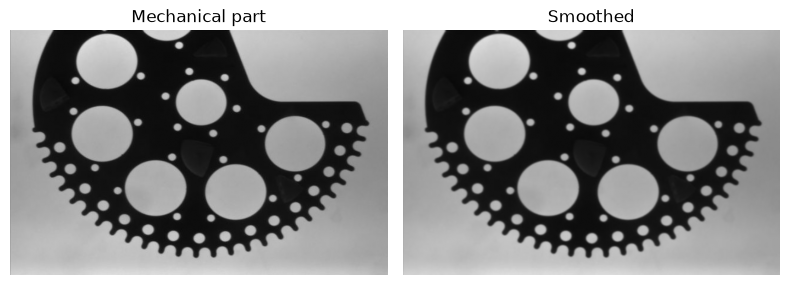

In [2]:
gray = read_image(ASSETS / "pdf/mechanical_part.png", gray=True)
blurred = cv2.GaussianBlur(gray, (3, 3), 0)
show_images({"Mechanical part": gray, "Smoothed": blurred}, cols=2)


## 3. 方向梯度、L1 合成与显示

绝对值再转换用于显示；合成计算保留浮点数，避免 uint8 相加饱和。常量图梯度为零时单独处理，避免除零。


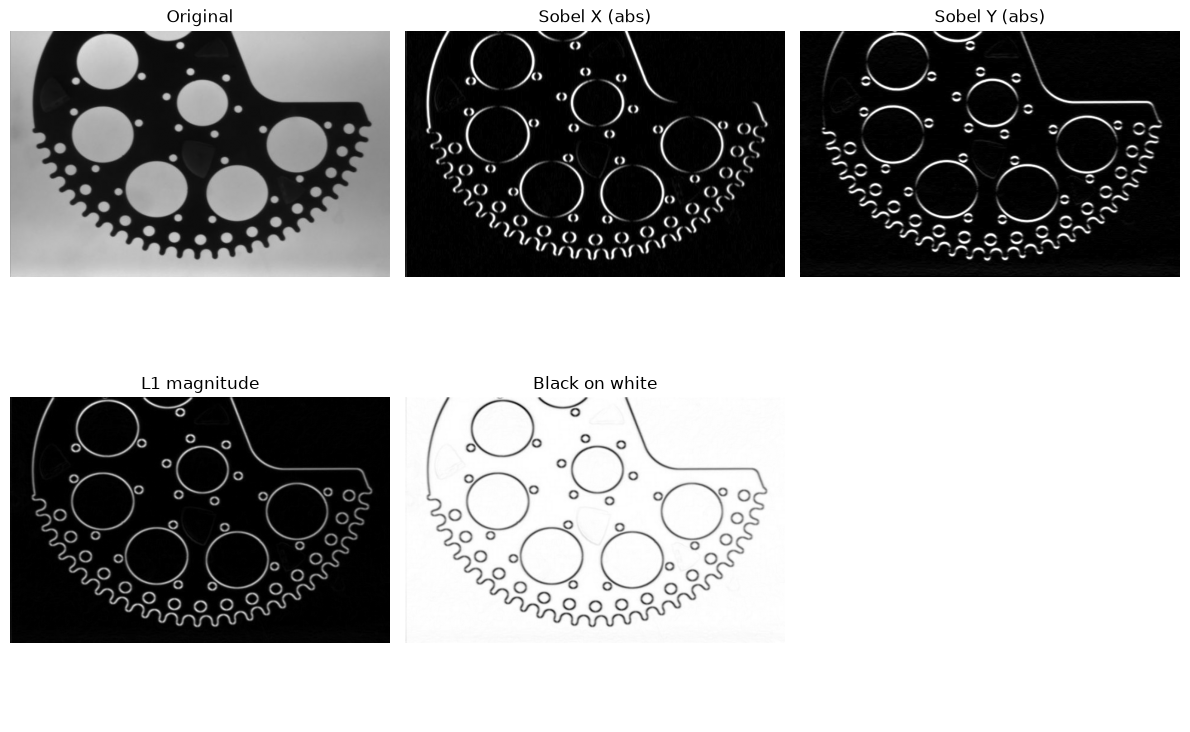

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab09/sobel_black_on_white.png')

In [3]:
gx = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)
abs_x = cv2.convertScaleAbs(gx)
abs_y = cv2.convertScaleAbs(gy)
magnitude_l1 = np.abs(gx) + np.abs(gy)
def normalize_u8(a):
    maximum = float(a.max())
    return np.zeros(a.shape, dtype=np.uint8) if maximum == 0 else np.clip(a * (255.0 / maximum), 0, 255).astype(np.uint8)

edges = normalize_u8(magnitude_l1)
black_on_white = 255 - edges
assert normalize_u8(np.zeros((8, 8), dtype=np.float32)).max() == 0
show_images({"Original": gray, "Sobel X (abs)": abs_x, "Sobel Y (abs)": abs_y,
             "L1 magnitude": edges, "Black on white": black_on_white}, cols=3,
            save_to=OUT / "sobel_comparison.png")
save_image(OUT / "sobel_magnitude.png", edges)
save_image(OUT / "sobel_black_on_white.png", black_on_white)


## 4. 比较阈值，并计算 L2 梯度

在归一化的边缘强度上设阈值；阈值越高通常保留越少的边缘。再计算欧氏长度 L2，与前面的 L1 合成结果比较。


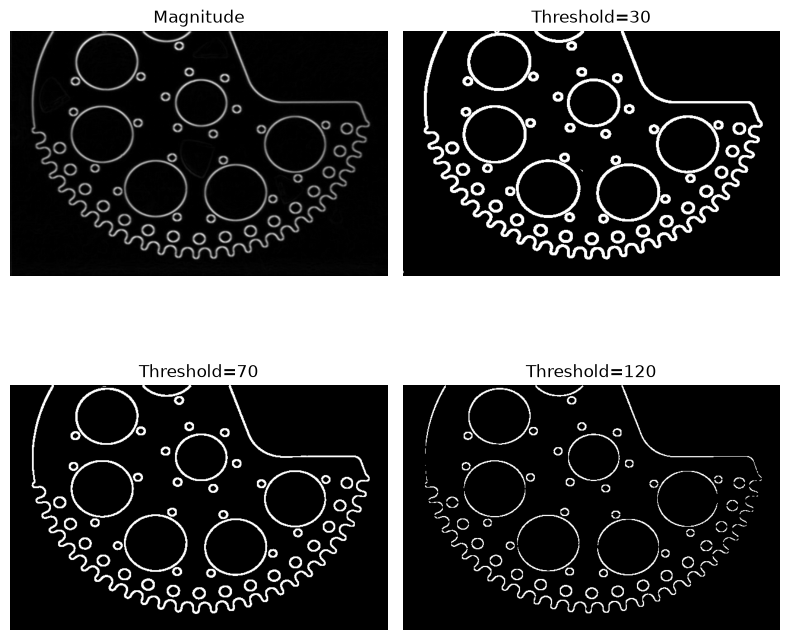

各阈值的边缘像素数: [28102, 20003, 11978]


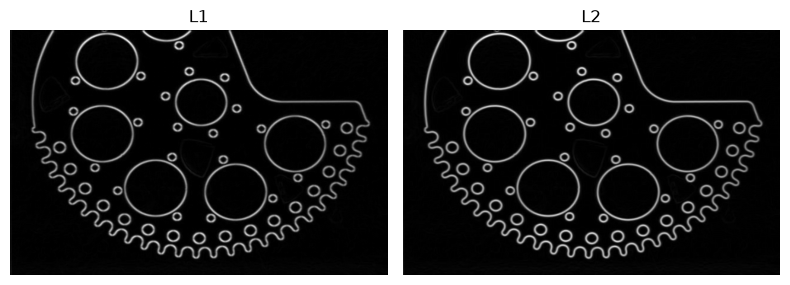

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab09/sobel_l2.png')

In [4]:
comparisons = {"Magnitude": edges}
counts = []
for threshold in (30, 70, 120):
    _, binary = cv2.threshold(edges, threshold, 255, cv2.THRESH_BINARY)
    comparisons[f"Threshold={threshold}"] = binary
    counts.append(int(np.count_nonzero(binary)))
    save_image(OUT / f"edges_threshold_{threshold}.png", binary)
assert counts[0] >= counts[1] >= counts[2]
show_images(comparisons, cols=2, save_to=OUT / "threshold_comparison.png")
print("各阈值的边缘像素数:", counts)
l2 = normalize_u8(cv2.magnitude(gx, gy))
show_images({"L1": edges, "L2": l2}, cols=2)
save_image(OUT / "sobel_l2.png", l2)


## 5. 迁移到熊猫图

毛发和竹叶有大量纹理，边缘提取结果与轮廓清晰的工业零件不同。


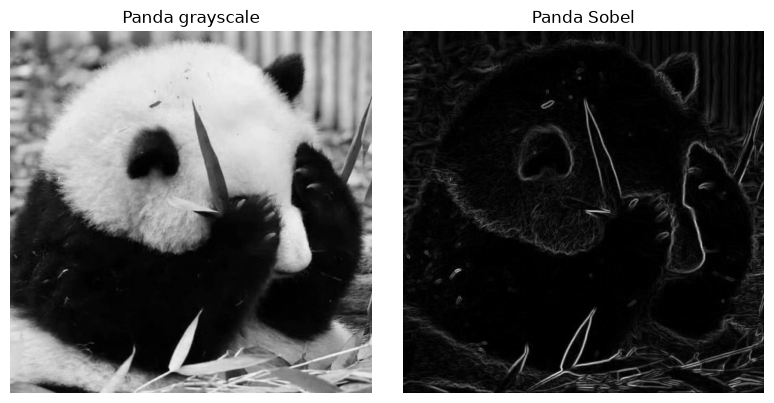

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab09/panda_edges.png')

In [5]:
panda = read_image(ASSETS / "user/panda.jpg", gray=True)
panda_smooth = cv2.GaussianBlur(panda, (5, 5), 1.2)
px = cv2.Sobel(panda_smooth, cv2.CV_32F, 1, 0, ksize=3)
py = cv2.Sobel(panda_smooth, cv2.CV_32F, 0, 1, ksize=3)
panda_edges = normalize_u8(cv2.magnitude(px, py))
show_images({"Panda grayscale": panda, "Panda Sobel": panda_edges}, cols=2)
save_image(OUT / "panda_edges.png", panda_edges)


## 记录与思考

1. Sobel x 为什么对竖直边缘响应强？
2. 若直接用 CV_8U 计算梯度，会丢失什么？
3. L1 与 L2 合成的数值和外观有什么差别？
4. 高阈值为何可能漏掉弱边缘？
5. 边缘图与完整物体轮廓是否等价？

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab09/`；运行本 Notebook 不会改写原始素材。
